# Linked flow

Draw a Gaussian source, pair it with a three-mode Gaussian mixture, and fit a
small MLP to the paired displacements. Everything is defined here; only JAX,
Equinox, Optax, SciPy and Matplotlib are needed.

The generator is $G_\theta(z)=z+f_\theta(z)$. Train with
$\mathcal L=\frac1N\sum_i|G_\theta(z_i)-x_{\pi(i)}|^2$.
Generation uses one network evaluation for $z\rightarrow x$. The plotted paths are
$x_t=(1-t)z+tG_\theta(z)$, for $0\leq t\leq1$.

In [13]:
import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import optax
from scipy.optimize import linear_sum_assignment
from scipy.stats import norm
import matplotlib.pyplot as plt

## Draw data and pair it

Use 1,024 points so SciPy's dense assignment stays small. Pair once by minimizing
the total squared distance. In 1D, sorting both samples is an equivalent shortcut.

In [14]:
key = jr.key(0)
key, kz, kc, kx, km, keval = jr.split(key, 6)

n = 1024

means = jnp.array([-2., 0., 2.])
sigma = 0.35
z = jr.normal(kz, (n, 1))
components = jr.randint(kc, (n, 1), 0, means.size)

x = means[components] + sigma * jr.normal(kx, (n, 1))

rows, columns = linear_sum_assignment((z - x.T)**2)
z, x = z[rows], x[columns]

## Train transport network 

Minibatches select from the same fixed pairs throughout training.

In [15]:
model = eqx.nn.MLP(1, 1, width_size=64, depth=2, activation=jnp.tanh, key=km)
optimizer = optax.adam(1e-3)
state = optimizer.init(eqx.filter(model, eqx.is_inexact_array))

def mse(model, z, x):
    return jnp.mean(jnp.square(jnp.subtract(z + jax.vmap(model)(z), x)))

@eqx.filter_jit
def step(model, state, z, x):
    loss, grads = eqx.filter_value_and_grad(mse)(model, z, x)
    updates, state = optimizer.update(grads, state, model)
    return eqx.apply_updates(model, updates), state, loss

for _ in range(5000):
    key, batch_key = jr.split(key)
    indices = jr.randint(batch_key, (256,), 0, n)
    model, state, loss = step(model, state, z[indices], x[indices])

## Generate and plot linked paths

Use fresh Gaussian inputs. Black curves are the analytic source and target PDFs. We plot the red histogram and straight paths come from the learned generator. 

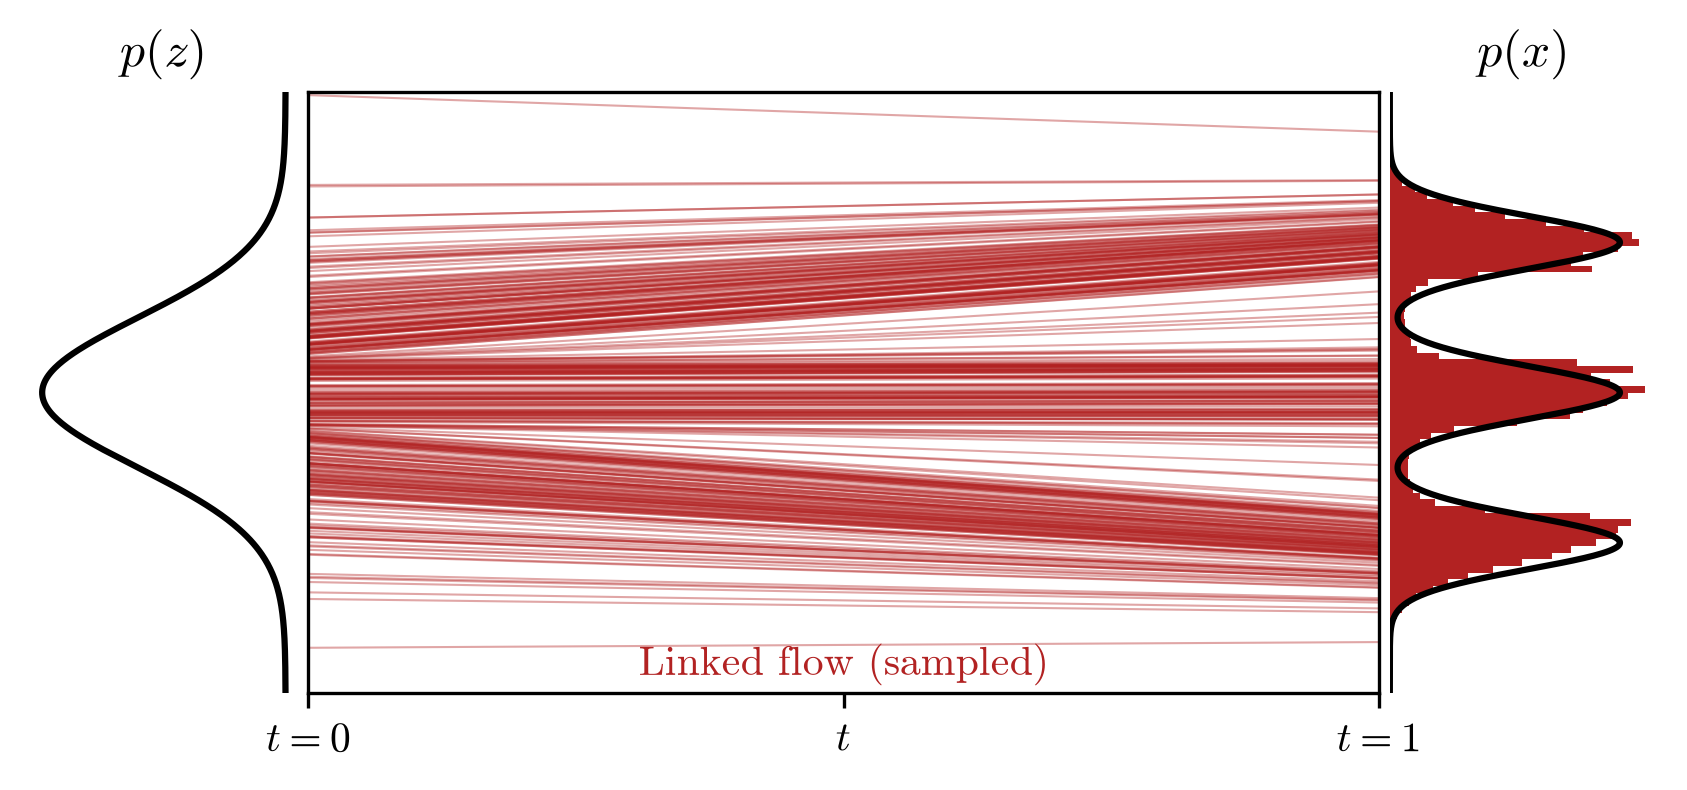

In [16]:
z_new = jr.normal(keval, (100_000, 1))
x_new = z_new + jax.vmap(model)(z_new)
grid = jnp.linspace(-4., 4., 500)

plt.rcParams.update({"font.family": "serif", "font.serif": ["cmr10"],
                     "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True})
fig, (left, center, right) = plt.subplots(
    1, 3, figsize=(7, 2.6), sharey=True, dpi=300,
    gridspec_kw={"width_ratios": [1, 4, 1], "wspace": 0.02},
)
left.plot(norm.pdf(grid), grid, color="black")
left.invert_xaxis()
left.set_title(r"$p(z)$")
left.set_axis_off()

center.plot([0, 1], jnp.stack([z_new[:400, 0], x_new[:400, 0]]),
            color="firebrick", linewidth=0.5, alpha=0.4)
center.set(xlim=(0, 1), ylim=(-4, 4), yticks=[], xticks=[0, 0.5, 1],
           xticklabels=[r"$t=0$", r"$t$", r"$t=1$"])
center.text(0.5, 0.03, "Linked flow (sampled)", color="firebrick",
            ha="center", transform=center.transAxes)

right.hist(x_new[:, 0], bins=90, range=(-4, 4), density=True,
           orientation="horizontal", color="firebrick")
right.plot(norm.pdf(grid[:, None], loc=means, scale=sigma).mean(axis=1),
           grid, color="black")
right.set_title(r"$p(x)$")
right.set_axis_off()
plt.show()